<a href="https://colab.research.google.com/github/Kothaveerababu1/Bank-Management-System-ATM-Application/blob/main/Animal_Image_Classification_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Animal Image Classification using CNN

## 1. Project Overview

This project implements an end-to-end **Animal Image Classification** system using Convolutional Neural Networks (CNNs) and the **Animals-10** dataset from Hugging Face.

The objective is to compare four CNN architectures and study how normalization and regularization affect learning and generalization:

1. **CNN1:** Basic CNN.
2. **CNN2:** CNN with Batch Normalization.
3. **CNN3:** CNN with L1 regularization.
4. **CNN4:** CNN with Batch Normalization, L2 regularization, and Dropout.

The notebook uses a stratified 70/10/20 training, validation, and test split. The validation set is used for model selection. The test set is reserved for the final evaluation of the selected model.

## 2. Dataset Acquisition and Preparation

The notebook downloads `Rapidata/Animals-10` from Hugging Face. Each image is converted to RGB and stored in class-specific folders so that TensorFlow's `flow_from_directory()` can load the data.

The first execution may take some time because the images must be downloaded and written to the Colab runtime.

In [ ]:
# 2.1 Imports and reproducibility
import os
import shutil
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, GlobalAveragePooling2D,
    Dense, Dropout, BatchNormalization
)
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from IPython.display import display
from google.colab import files

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# 2.2 Download the dataset
dataset = load_dataset("Rapidata/Animals-10", split="train")

class_names = dataset.features["label"].names
NUM_CLASSES = len(class_names)

print(f"Total images: {len(dataset):,}")
print(f"Number of classes: {NUM_CLASSES}")
print("Classes:", class_names)

README.md:   0%|          | 0.00/1.94k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  319MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23554 [00:00<?, ? examples/s]

Total images: 23,554
Number of classes: 10
Classes: ['Butterfly', 'Cat', 'Chicken', 'Cow', 'Dog', 'Elephant', 'Horse', 'Sheep', 'Spider', 'Squirrel']


## 3. Stratified 70/10/20 Dataset Split

The dataset is divided into:

- **70% training:** used to update model weights.
- **10% validation:** used to monitor learning and select the best model.
- **20% testing:** kept separate until the final evaluation.

Stratification preserves the approximate class proportions in each subset. A fixed random seed makes the split reproducible.

In [ ]:
# 3.1 Create reproducible stratified indices
all_indices = np.arange(len(dataset))
all_targets = np.asarray(dataset["label"])

train_indices, temporary_indices = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=all_targets
)

temporary_targets = all_targets[temporary_indices]
validation_indices, test_indices = train_test_split(
    temporary_indices,
    test_size=2/3,
    random_state=SEED,
    stratify=temporary_targets
)

# Verify split integrity before writing images
train_set = set(train_indices.tolist())
validation_set = set(validation_indices.tolist())
test_set = set(test_indices.tolist())

assert train_set.isdisjoint(validation_set)
assert train_set.isdisjoint(test_set)
assert validation_set.isdisjoint(test_set)
assert len(train_indices) + len(validation_indices) + len(test_indices) == len(dataset)

print(f"Training:   {len(train_indices):,} ({len(train_indices)/len(dataset):.1%})")
print(f"Validation: {len(validation_indices):,} ({len(validation_indices)/len(dataset):.1%})")
print(f"Testing:    {len(test_indices):,} ({len(test_indices)/len(dataset):.1%})")
print("No overlap between split indices.")

Training:   16,487 (70.0%)
Validation: 2,355 (10.0%)
Testing:    4,712 (20.0%)
No overlap between split indices.


In [ ]:
# 3.2 Write RGB images into class-specific directories
base_dir = "/content/animal_dataset_v2"

if os.path.exists(base_dir):
    shutil.rmtree(base_dir)

split_indices = {
    "train": train_indices,
    "val": validation_indices,
    "test": test_indices
}

for split_name in split_indices:
    for class_name in class_names:
        os.makedirs(os.path.join(base_dir, split_name, class_name), exist_ok=True)

for split_name, indices in split_indices.items():
    for dataset_index in indices:
        sample = dataset[int(dataset_index)]
        label_name = class_names[int(sample["label"])]
        image_obj = sample["image"].convert("RGB")
        image_path = os.path.join(
            base_dir, split_name, label_name, f"{int(dataset_index)}.jpg"
        )
        image_obj.save(image_path, format="JPEG", quality=95)

print("Images saved into:", base_dir)

Images saved into: /content/animal_dataset_v2


### 3.3 Dataset Verification

The following checks confirm that each split contains the expected classes and that the saved image counts agree with the stratified indices.

In [ ]:
# Verify per-class counts in each saved split
split_count_rows = []
for split_name, indices in split_indices.items():
    counts = {name: 0 for name in class_names}
    for dataset_index in indices:
        label_id = int(all_targets[int(dataset_index)])
        counts[class_names[label_id]] += 1

    for class_name, count in counts.items():
        split_count_rows.append({
            "Split": split_name,
            "Class": class_name,
            "Images": count
        })

split_counts_df = pd.DataFrame(split_count_rows)
display(split_counts_df.pivot(index="Class", columns="Split", values="Images"))

for split_name in ["train", "val", "test"]:
    split_root = Path(base_dir) / split_name
    missing = [name for name in class_names if not list((split_root / name).glob("*.jpg"))]
    assert not missing, f"Missing classes in {split_name}: {missing}"

print("Dataset verification passed: all classes are represented in all splits.")

Split,test,train,val
Class,,,
Butterfly,321,1122,160
Cat,240,839,120
Chicken,599,2095,299
Cow,360,1258,179
Dog,962,3368,481
Elephant,207,726,104
Horse,520,1818,260
Sheep,275,963,138
Spider,868,3038,434


Dataset verification passed: all classes are represented in all splits.


## 4. Image Preprocessing and Data Augmentation

All images are resized to **128 × 128 pixels** and loaded as RGB images. Pixel values are rescaled to the range 0–1.

Augmentation is applied only to the training data. Validation and test images are only rescaled so that evaluation remains deterministic.

In [ ]:
# 4.1 Configure image generators
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
MAX_EPOCHS = 15

train_datagen = ImageDataGenerator(
    rescale=1.0/255.0,
    rotation_range=30,
    zoom_range=0.2,
    shear_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest"
)

evaluation_datagen = ImageDataGenerator(rescale=1.0/255.0)

train_generator = train_datagen.flow_from_directory(
    os.path.join(base_dir, "train"),
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_generator = evaluation_datagen.flow_from_directory(
    os.path.join(base_dir, "val"),
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Keep test generator available, but do not use it until Section 8.
test_generator = evaluation_datagen.flow_from_directory(
    os.path.join(base_dir, "test"),
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="categorical",
    batch_size=BATCH_SIZE,
    shuffle=False
)

NUM_CLASSES = train_generator.num_classes
class_labels = [
    name for name, index in sorted(
        train_generator.class_indices.items(), key=lambda item: item[1]
    )
]

assert train_generator.class_indices == val_generator.class_indices
assert train_generator.class_indices == test_generator.class_indices
assert NUM_CLASSES == len(class_labels)

print("Class indices:", train_generator.class_indices)
print("All generators use consistent class indices.")

Found 16487 images belonging to 10 classes.
Found 2355 images belonging to 10 classes.
Found 4712 images belonging to 10 classes.
Class indices: {'Butterfly': 0, 'Cat': 1, 'Chicken': 2, 'Cow': 3, 'Dog': 4, 'Elephant': 5, 'Horse': 6, 'Sheep': 7, 'Spider': 8, 'Squirrel': 9}
All generators use consistent class indices.


## 5. Evaluation Functions and Training Callbacks

During the four experiments, only training and validation histories are collected. **No test-set evaluation is performed in this section.**

Each model receives newly created callback instances. Early stopping restores the weights from the epoch with the best validation loss, while the learning-rate callback reduces the learning rate when validation loss stops improving.

In [ ]:
# 5.1 Result and history registries
results_dict = {}
histories = {}
trained_models = {}

def plot_training_history(history, model_name):
    """Plot training/validation accuracy and loss for one experiment."""
    history_data = history.history

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(history_data["accuracy"], label="Training accuracy")
    axes[0].plot(history_data["val_accuracy"], label="Validation accuracy")
    axes[0].set_title(f"{model_name} - Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history_data["loss"], label="Training loss")
    axes[1].plot(history_data["val_loss"], label="Validation loss")
    axes[1].set_title(f"{model_name} - Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

def record_validation_results(model_name, history):
    """Record best validation metrics; this function never accesses test data."""
    val_losses = np.asarray(history.history["val_loss"], dtype=float)
    best_epoch_index = int(np.argmin(val_losses))

    results_dict[model_name] = {
        "Best Validation Loss": float(val_losses[best_epoch_index]),
        "Validation Accuracy at Best Loss": float(
            history.history["val_accuracy"][best_epoch_index]
        ),
        "Epochs Completed": len(history.history["loss"]),
        "Best Epoch": best_epoch_index + 1
    }

    histories[model_name] = history
    return results_dict[model_name]

def create_fresh_callbacks():
    """Return new callback objects for each model fit."""
    return [
        EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
            mode="min",
            verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
            mode="min",
            verbose=1
        )
    ]

## 6. CNN Model Experiments

Four custom CNN architectures are trained using the same training and validation generators. Each model has a softmax output layer sized dynamically to the number of dataset classes.

The model designs retain the intended comparison: baseline, Batch Normalization, L1 regularization, and Batch Normalization with L2 regularization and Dropout.

### 6.1 CNN1 – Basic CNN

CNN1 is the baseline architecture. It uses convolution, max-pooling, global average pooling, and dense layers without Batch Normalization, L1/L2 regularization, or Dropout.

Epoch 1/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 117s 206ms/step - accuracy: 0.2279 - loss: 2.1003 - val_accuracy: 0.2501 - val_loss: 2.0816 - learning_rate: 0.0010
Epoch 2/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 96s 187ms/step - accuracy: 0.2885 - loss: 1.9635 - val_accuracy: 0.2730 - val_loss: 2.0965 - learning_rate: 0.0010
Epoch 3/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 99s 191ms/step - accuracy: 0.3583 - loss: 1.8278 - val_accuracy: 0.3851 - val_loss: 1.7676 - learning_rate: 0.0010
Epoch 4/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 94s 182ms/step - accuracy: 0.3995 - loss: 1.7164 - val_accuracy: 0.3605 - val_loss: 1.8965 - learning_rate: 0.0010
Epoch 5/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.4254 - loss: 1.6323
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
516/516 ━━━━━━━━━━━━━━━━━━━━ 94s 182ms/step - accuracy: 0.4371 - loss: 1.6197 - val_accuracy: 0.3584 - val_loss: 1.9925 - learning_rate: 0.0010
Epoch 6/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 95s 183ms/step - accuracy: 0.47

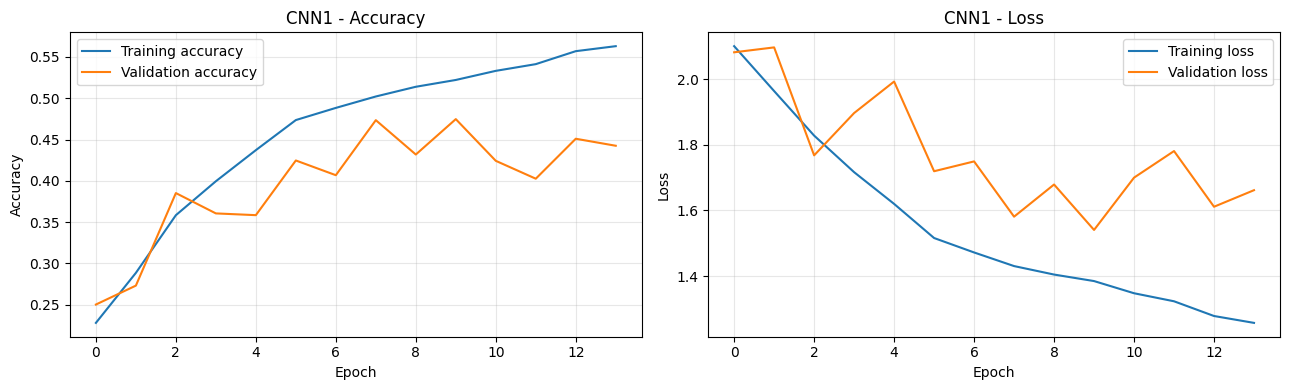

In [ ]:
# CNN1: Basic CNN
CNN1 = Sequential([
    Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dense(NUM_CLASSES, activation="softmax")
])

CNN1.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history1 = CNN1.fit(
    train_generator,
    epochs=MAX_EPOCHS,
    validation_data=val_generator,
    callbacks=create_fresh_callbacks()
)

CNN1.save("CNN1.keras")
trained_models["CNN1"] = CNN1
record_validation_results("CNN1", history1)
plot_training_history(history1, "CNN1")

### 6.2 CNN2 – CNN with Batch Normalization

CNN2 adds Batch Normalization after convolutional layers and the hidden dense layer. It does not use L1/L2 regularization or Dropout.

Epoch 1/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 108s 194ms/step - accuracy: 0.3702 - loss: 1.8243 - val_accuracy: 0.3550 - val_loss: 1.8792 - learning_rate: 0.0010
Epoch 2/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 95s 183ms/step - accuracy: 0.4746 - loss: 1.5145 - val_accuracy: 0.3792 - val_loss: 2.0718 - learning_rate: 0.0010
Epoch 3/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.5276 - loss: 1.3544
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
516/516 ━━━━━━━━━━━━━━━━━━━━ 95s 183ms/step - accuracy: 0.5402 - loss: 1.3342 - val_accuracy: 0.2998 - val_loss: 2.9620 - learning_rate: 0.0010
Epoch 4/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 95s 183ms/step - accuracy: 0.5997 - loss: 1.1715 - val_accuracy: 0.5996 - val_loss: 1.2160 - learning_rate: 5.0000e-04
Epoch 5/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 92s 179ms/step - accuracy: 0.6266 - loss: 1.0932 - val_accuracy: 0.6106 - val_loss: 1.1536 - learning_rate: 5.0000e-04
Epoch 6/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 97s 188ms/step - accura

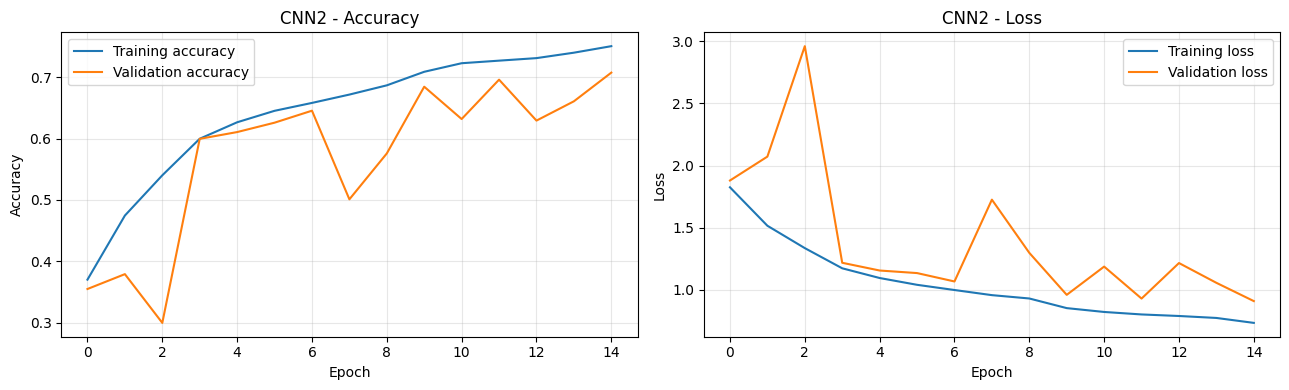

In [ ]:
# CNN2: CNN with Batch Normalization only
CNN2 = Sequential([
    Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    Conv2D(32, (3, 3), activation="relu"),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(128, (3, 3), activation="relu"),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    BatchNormalization(),
    Dense(NUM_CLASSES, activation="softmax")
])

CNN2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history2 = CNN2.fit(
    train_generator,
    epochs=MAX_EPOCHS,
    validation_data=val_generator,
    callbacks=create_fresh_callbacks()
)

CNN2.save("CNN2.keras")
trained_models["CNN2"] = CNN2
record_validation_results("CNN2", history2)
plot_training_history(history2, "CNN2")

### 6.3 CNN2 Diagnostic Analysis

This diagnostic uses the actual training history generated by CNN2. It reports the epoch with the lowest validation loss and compares the training and validation metrics at that epoch. The analysis does not assume a cause for any observed behaviour.

In [ ]:
# CNN2 diagnostics based on this run's recorded history
cnn2_val_losses = np.asarray(history2.history["val_loss"], dtype=float)
cnn2_best_idx = int(np.argmin(cnn2_val_losses))

print(f"CNN2 completed epochs: {len(history2.history['loss'])}")
print(f"Lowest validation loss: {cnn2_val_losses[cnn2_best_idx]:.4f}")
print(f"Best validation-loss epoch: {cnn2_best_idx + 1}")
print(
    f"Training accuracy at that epoch: "
    f"{history2.history['accuracy'][cnn2_best_idx]:.4f}"
)
print(
    f"Validation accuracy at that epoch: "
    f"{history2.history['val_accuracy'][cnn2_best_idx]:.4f}"
)
print(
    "Early stopping restores the weights from the epoch with the best "
    "validation loss when training stops."
)

CNN2 completed epochs: 15
Lowest validation loss: 0.9071
Best validation-loss epoch: 15
Training accuracy at that epoch: 0.7505
Validation accuracy at that epoch: 0.7074
Early stopping restores the weights from the epoch with the best validation loss when training stops.


### 6.4 CNN3 – CNN with L1 Regularization

CNN3 applies L1 regularization to the convolutional kernels and hidden dense layer. L1 regularization adds a penalty based on the absolute values of the weights.

Epoch 1/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 105s 195ms/step - accuracy: 0.2006 - loss: 2.2634 - val_accuracy: 0.2042 - val_loss: 2.2040 - learning_rate: 0.0010
Epoch 2/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 94s 182ms/step - accuracy: 0.1985 - loss: 2.1969 - val_accuracy: 0.2042 - val_loss: 2.1877 - learning_rate: 0.0010
Epoch 3/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 95s 185ms/step - accuracy: 0.2043 - loss: 2.1856 - val_accuracy: 0.2161 - val_loss: 2.1824 - learning_rate: 0.0010
Epoch 4/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 95s 184ms/step - accuracy: 0.2097 - loss: 2.1774 - val_accuracy: 0.2110 - val_loss: 2.1696 - learning_rate: 0.0010
Epoch 5/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 93s 181ms/step - accuracy: 0.2178 - loss: 2.1648 - val_accuracy: 0.2276 - val_loss: 2.1568 - learning_rate: 0.0010
Epoch 6/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 93s 180ms/step - accuracy: 0.2227 - loss: 2.1545 - val_accuracy: 0.2157 - val_loss: 2.1548 - learning_rate: 0.0010
Epoch 7/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 96s 187ms/step - accuracy: 0.

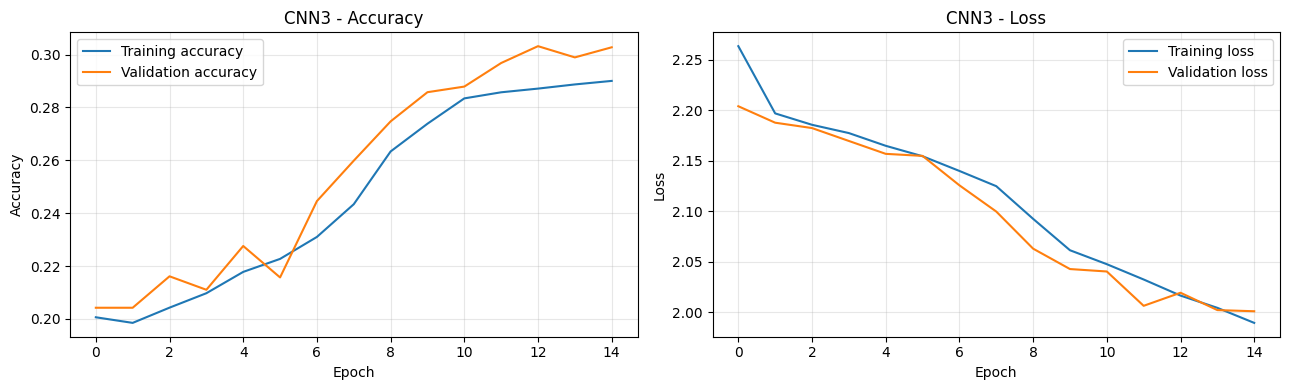

In [ ]:
# CNN3: CNN with L1 regularization only
CNN3 = Sequential([
    Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    Conv2D(32, (3, 3), activation="relu",
           kernel_regularizer=regularizers.l1(0.0001)),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), activation="relu",
           kernel_regularizer=regularizers.l1(0.0001)),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(128, (3, 3), activation="relu",
           kernel_regularizer=regularizers.l1(0.0001)),
    MaxPooling2D(pool_size=(2, 2)),
    GlobalAveragePooling2D(),
    Dense(128, activation="relu",
          kernel_regularizer=regularizers.l1(0.0001)),
    Dense(NUM_CLASSES, activation="softmax")
])

CNN3.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history3 = CNN3.fit(
    train_generator,
    epochs=MAX_EPOCHS,
    validation_data=val_generator,
    callbacks=create_fresh_callbacks()
)

CNN3.save("CNN3.keras")
trained_models["CNN3"] = CNN3
record_validation_results("CNN3", history3)
plot_training_history(history3, "CNN3")

### 6.5 CNN4 – CNN with Batch Normalization, L2 Regularization and Dropout

CNN4 combines Batch Normalization, L2 kernel regularization, and Dropout (rate 0.5). L2 regularization penalizes large weights, while Dropout randomly deactivates a proportion of units during training.

Epoch 1/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 108s 196ms/step - accuracy: 0.2549 - loss: 2.6005 - val_accuracy: 0.3023 - val_loss: 2.3200 - learning_rate: 0.0010
Epoch 2/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 98s 191ms/step - accuracy: 0.3796 - loss: 2.0596 - val_accuracy: 0.2735 - val_loss: 2.6557 - learning_rate: 0.0010
Epoch 3/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.4343 - loss: 1.8807
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
516/516 ━━━━━━━━━━━━━━━━━━━━ 98s 189ms/step - accuracy: 0.4417 - loss: 1.8471 - val_accuracy: 0.3507 - val_loss: 2.3680 - learning_rate: 0.0010
Epoch 4/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 98s 189ms/step - accuracy: 0.4998 - loss: 1.6495 - val_accuracy: 0.3346 - val_loss: 2.3368 - learning_rate: 5.0000e-04
Epoch 5/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 96s 186ms/step - accuracy: 0.5382 - loss: 1.5456 - val_accuracy: 0.4807 - val_loss: 1.6777 - learning_rate: 5.0000e-04
Epoch 6/15
516/516 ━━━━━━━━━━━━━━━━━━━━ 97s 188ms/step - accura

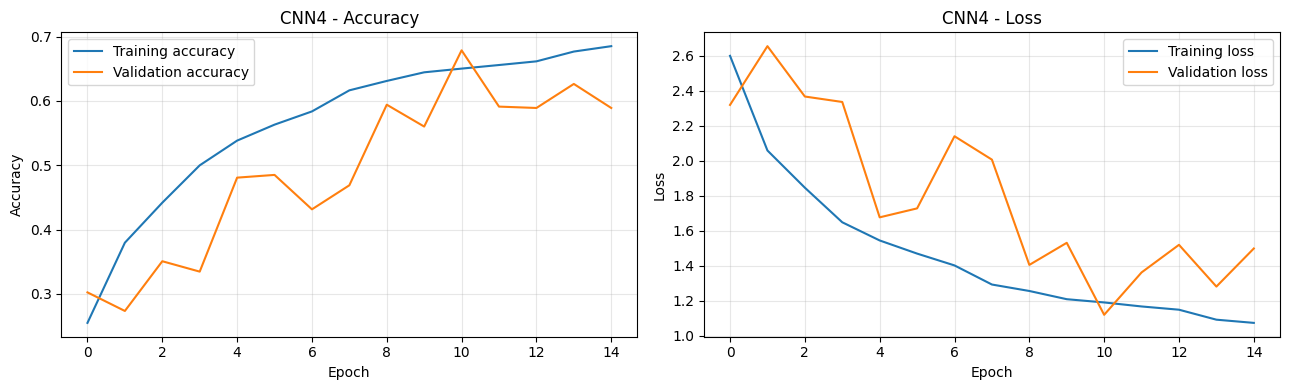

In [ ]:
# CNN4: Batch Normalization + L2 regularization + Dropout
CNN4 = Sequential([
    Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    Conv2D(32, (3, 3), activation="relu",
           kernel_regularizer=regularizers.l2(0.001)),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(64, (3, 3), activation="relu",
           kernel_regularizer=regularizers.l2(0.001)),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(128, (3, 3), activation="relu",
           kernel_regularizer=regularizers.l2(0.001)),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),
    GlobalAveragePooling2D(),
    Dense(128, activation="relu",
          kernel_regularizer=regularizers.l2(0.001)),
    BatchNormalization(),
    Dropout(0.5),
    Dense(NUM_CLASSES, activation="softmax")
])

CNN4.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history4 = CNN4.fit(
    train_generator,
    epochs=MAX_EPOCHS,
    validation_data=val_generator,
    callbacks=create_fresh_callbacks()
)

CNN4.save("CNN4.keras")
trained_models["CNN4"] = CNN4
record_validation_results("CNN4", history4)
plot_training_history(history4, "CNN4")

## 7. Model Comparison and Validation-Based Selection

The four experiments are compared using their **minimum validation loss**. Validation accuracy is reported at the epoch where that minimum validation loss occurred.

The test dataset is not used for this comparison or for selecting the winning model.

In [ ]:
# Build and display validation-only comparison table
comparison_df = pd.DataFrame.from_dict(results_dict, orient="index")
comparison_df.index.name = "Model"
comparison_df = comparison_df.sort_values("Best Validation Loss")
display(comparison_df)

best_model_name = comparison_df["Best Validation Loss"].idxmin()
best_model_path = f"{best_model_name}.keras"

print(f"Selected model (minimum validation loss): {best_model_name}")
print(f"Best validation loss: {comparison_df.loc[best_model_name, 'Best Validation Loss']:.4f}")
print(
    "Validation accuracy at that epoch: "
    f"{comparison_df.loc[best_model_name, 'Validation Accuracy at Best Loss']:.4f}"
)
print("Saved model:", best_model_path)

,Best Validation Loss,Validation Accuracy at Best Loss,Epochs Completed,Best Epoch
Model,,,,
CNN2,0.907102,0.707431,15,15
CNN4,1.120834,0.678556,15,11
CNN1,1.540357,0.474735,14,10
CNN3,2.001000,0.302760,15,15


Selected model (minimum validation loss): CNN2
Best validation loss: 0.9071
Validation accuracy at that epoch: 0.7074
Saved model: CNN2.keras


## 8. Final Test Evaluation

Only after selecting the winning model using validation loss do we evaluate it on the test dataset. The test generator is configured with `shuffle=False`, ensuring that predicted labels align with the true labels.

This section evaluates the selected model once and reports its final test metrics.

148/148 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 0.6957 - loss: 0.9520
148/148 ━━━━━━━━━━━━━━━━━━━━ 7s 43ms/step
Selected model: CNN2
Test loss: 0.9520
Test accuracy: 0.6957
Macro precision: 0.6886
Macro recall: 0.6792
Macro F1-score: 0.6581
Weighted precision: 0.7373
Weighted recall: 0.6957
Weighted F1-score: 0.6985

Classification Report:
              precision    recall  f1-score   support

   Butterfly       0.72      0.86      0.78       321
         Cat       0.70      0.38      0.49       240
     Chicken       0.72      0.88      0.79       599
         Cow       0.70      0.46      0.56       360
         Dog       0.83      0.56      0.67       962
    Elephant       0.31      0.86      0.45       207
       Horse       0.61      0.73      0.67       520
       Sheep       0.72      0.56      0.63       275
      Spider       0.88      0.84      0.86       868
    Squirrel       0.70      0.66      0.68       360

    accuracy                           0.70      4712
 

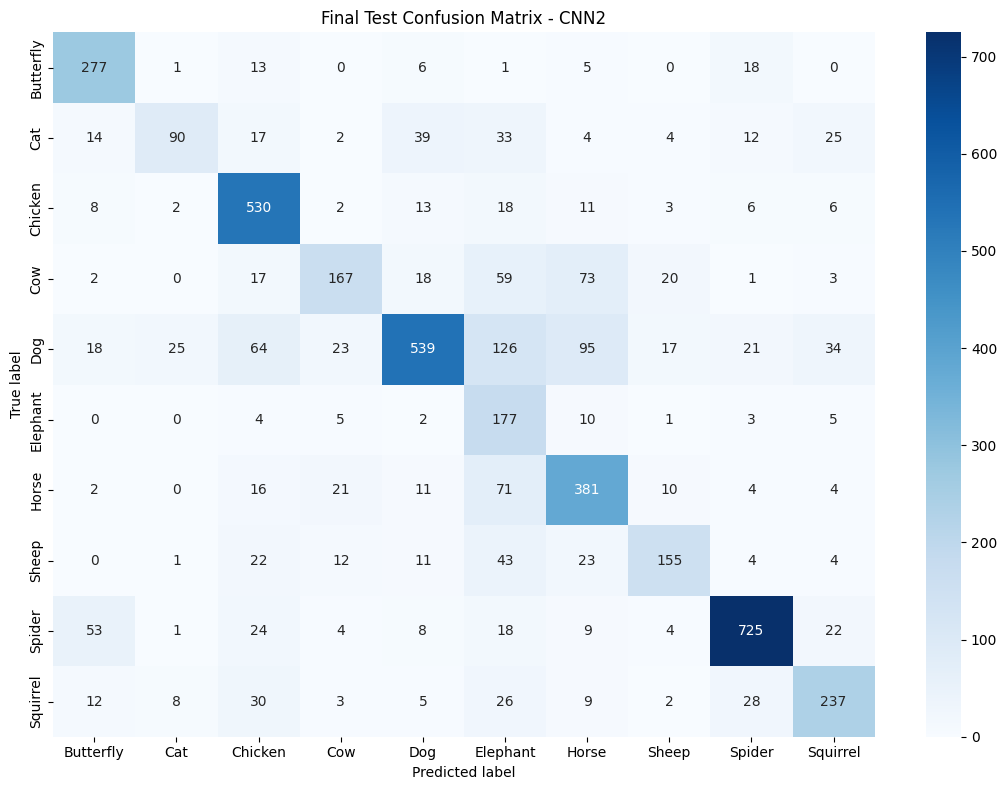

In [ ]:
# Load the validation-selected model and perform the final test evaluation once
best_model = load_model(best_model_path)

test_generator.reset()
test_loss, test_accuracy = best_model.evaluate(test_generator, verbose=1)

test_generator.reset()
test_probabilities = best_model.predict(test_generator, verbose=1)
test_predictions = np.argmax(test_probabilities, axis=1)
test_true_labels = test_generator.classes

assert len(test_predictions) == len(test_true_labels)

test_report_text = classification_report(
    test_true_labels,
    test_predictions,
    target_names=class_labels,
    zero_division=0
)
test_report_dict = classification_report(
    test_true_labels,
    test_predictions,
    target_names=class_labels,
    output_dict=True,
    zero_division=0
)

macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    test_true_labels, test_predictions, average="macro", zero_division=0
)
weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(
    test_true_labels, test_predictions, average="weighted", zero_division=0
)

print(f"Selected model: {best_model_name}")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Macro precision: {macro_precision:.4f}")
print(f"Macro recall: {macro_recall:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")
print(f"Weighted precision: {weighted_precision:.4f}")
print(f"Weighted recall: {weighted_recall:.4f}")
print(f"Weighted F1-score: {weighted_f1:.4f}")

print("\nClassification Report:")
print(test_report_text)

cm = confusion_matrix(test_true_labels, test_predictions)
plt.figure(figsize=(11, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_labels, yticklabels=class_labels
)
plt.title(f"Final Test Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

## 9. Training Performance and Results Summary

This section summarizes the validation-based comparison and the final test evaluation. The training curves below use the actual histories from the four experiments.

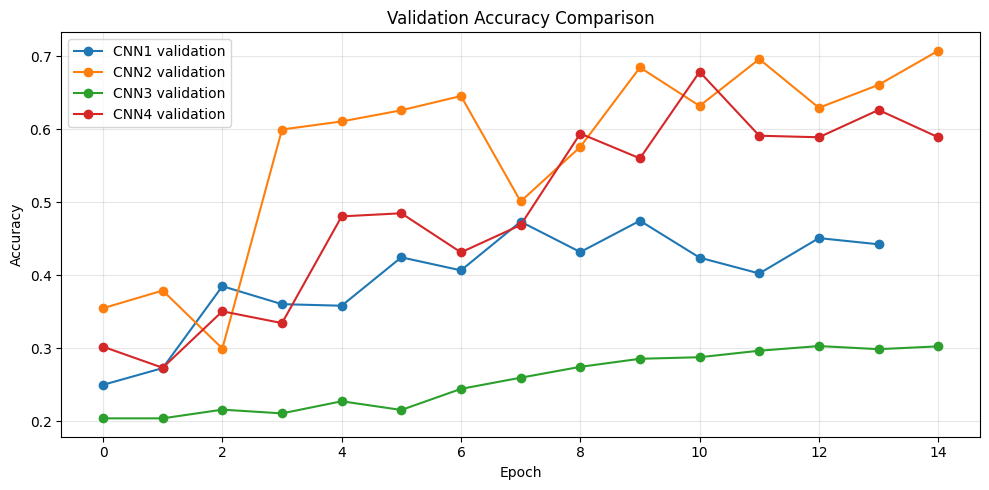

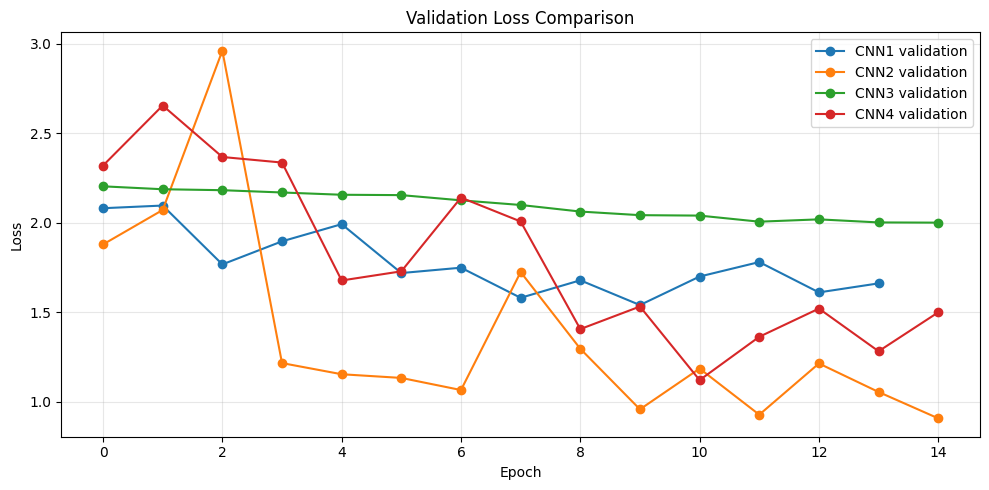

,Selected Model,Best Validation Loss,Validation Accuracy,Test Loss,Test Accuracy,Macro F1,Weighted F1
0,CNN2,0.907102,0.707431,0.951956,0.695671,0.658098,0.698475


Interpretation guide:
- Batch Normalization can help stabilize and speed up training.
- L1 regularization penalizes absolute weight magnitudes and can encourage sparsity.
- L2 regularization penalizes large weights and can reduce model complexity.
- Dropout reduces co-adaptation by randomly omitting units during training.
- The measured validation and test results determine which approach worked best in this run.


In [ ]:
# 9.1 Compare training and validation accuracy across all experiments
plt.figure(figsize=(10, 5))
for model_name, history in histories.items():
    plt.plot(history.history["val_accuracy"], marker="o", label=f"{model_name} validation")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 9.2 Compare training and validation loss across all experiments
plt.figure(figsize=(10, 5))
for model_name, history in histories.items():
    plt.plot(history.history["val_loss"], marker="o", label=f"{model_name} validation")
plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 9.3 Final results summary using measured values
final_summary = pd.DataFrame([{
    "Selected Model": best_model_name,
    "Best Validation Loss": float(comparison_df.loc[best_model_name, "Best Validation Loss"]),
    "Validation Accuracy": float(comparison_df.loc[best_model_name, "Validation Accuracy at Best Loss"]),
    "Test Loss": float(test_loss),
    "Test Accuracy": float(test_accuracy),
    "Macro F1": float(macro_f1),
    "Weighted F1": float(weighted_f1)
}])
display(final_summary)

print("Interpretation guide:")
print("- Batch Normalization can help stabilize and speed up training.")
print("- L1 regularization penalizes absolute weight magnitudes and can encourage sparsity.")
print("- L2 regularization penalizes large weights and can reduce model complexity.")
print("- Dropout reduces co-adaptation by randomly omitting units during training.")
print("- The measured validation and test results determine which approach worked best in this run.")

## 10. Interactive Animal Prediction Demo

Upload one or more image files to predict their animal classes using the model selected by minimum validation loss. Each uploaded image is converted to RGB, resized to 128 × 128, and normalized in the same way as the training images.

In [ ]:
def run_interactive_prediction_demo():
    """Upload images in Colab and classify them using the selected CNN model."""
    model_path = f"{best_model_name}.keras"
    predictor_model = load_model(model_path)

    uploaded_files = files.upload()
    if not uploaded_files:
        print("No files were uploaded.")
        return

    for file_name in uploaded_files.keys():
        try:
            img = image.load_img(
                file_name,
                target_size=IMG_SIZE,
                color_mode="rgb"
            )
            img_array = image.img_to_array(img).astype("float32") / 255.0
            img_batch = np.expand_dims(img_array, axis=0)

            probabilities = predictor_model.predict(img_batch, verbose=0)[0]
            predicted_index = int(np.argmax(probabilities))
            confidence = float(probabilities[predicted_index])
            predicted_class = class_labels[predicted_index]

            plt.figure(figsize=(5, 5))
            plt.imshow(img)
            plt.title(
                f"Predicted animal: {predicted_class}\n"
                f"Confidence: {confidence * 100:.2f}%"
            )
            plt.axis("off")
            plt.show()

            print(f"{file_name}: {predicted_class} ({confidence * 100:.2f}%)")

        except Exception as error:
            print(f"Could not process {file_name}: {error}")

## 11. Conclusion

This project compares four CNN architectures for multi-class animal image classification using the Animals-10 dataset. The experiments investigate a baseline CNN, Batch Normalization, L1 regularization, and a combined architecture using Batch Normalization, L2 regularization, and Dropout.

A stratified 70/10/20 split is used to separate training, validation, and test data. The winning model is selected exclusively using minimum validation loss, and the held-out test set is used only for the final evaluation. The final metrics and plots are generated from the actual training run.

The interactive demo allows new images to be uploaded and classified using the selected model.

### Optional Demo Execution

Run the following final code cell when you want to upload animal images and test the selected model interactively.

Saving butterfly.jpg to butterfly.jpg


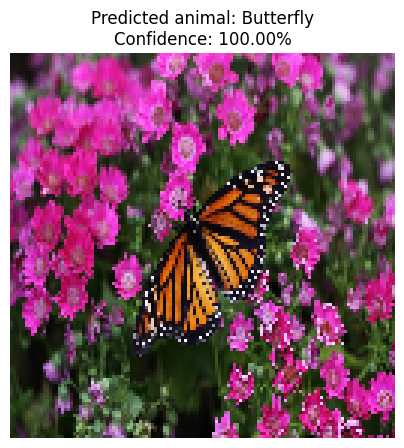

butterfly.jpg: Butterfly (100.00%)


In [ ]:
run_interactive_prediction_demo()

In [ ]:

# ============================================================
# ANIMALS-10 CNN IMAGE CLASSIFICATION - WEB INTERFACE
# Built using Gradio for Google Colab
# ============================================================

# 1. Install required libraries
!pip install -q gradio

# 2. Import libraries
import os
import gradio as gr
import numpy as np
import tensorflow as tf

from PIL import Image

# ============================================================
# 3. Configuration
# ============================================================

IMG_SIZE = (128, 128)

# Class order from the Animals-10 notebook
class_labels = [
    "Butterfly",
    "Cat",
    "Chicken",
    "Cow",
    "Dog",
    "Elephant",
    "Horse",
    "Sheep",
    "Spider",
    "Squirrel"
]

# Available trained models
model_files = {
    "CNN1 - Basic CNN": "CNN1.keras",
    "CNN2 - Batch Normalization": "CNN2.keras",
    "CNN3 - L1 Regularization": "CNN3.keras",
    "CNN4 - BN + L2 + Dropout": "CNN4.keras"
}

# ============================================================
# 4. Check and upload trained models if necessary
# ============================================================

missing_models = [
    filename for filename in model_files.values()
    if not os.path.exists(filename)
]

if missing_models:
    print("Some trained models are missing.")
    print("Please upload your .keras model files.")

    from google.colab import files
    uploaded = files.upload()

    print("Uploaded files:", list(uploaded.keys()))

# Check which models are available
available_models = {
    name: path
    for name, path in model_files.items()
    if os.path.exists(path)
}

if not available_models:
    raise FileNotFoundError(
        "No trained .keras model found. "
        "Upload at least one trained CNN model."
    )

print("Available models:", list(available_models.keys()))

# ============================================================
# 5. Load trained models
# ============================================================

loaded_models = {}

def get_model(model_name):

    if model_name not in loaded_models:

        model_path = available_models[model_name]

        loaded_models[model_name] = tf.keras.models.load_model(
            model_path,
            compile=False
        )

    return loaded_models[model_name]

# ============================================================
# 6. Prediction function
# ============================================================

def predict_animal(input_image, selected_model):

    if input_image is None:
        return "Please upload an image.", {}

    try:
        # Load selected CNN model
        model = get_model(selected_model)

        # Convert image to RGB
        img = input_image.convert("RGB")

        # Resize image to 128 x 128
        img = img.resize(IMG_SIZE)

        # Convert image into NumPy array
        img_array = np.array(img).astype("float32")

        # Normalize pixel values
        img_array = img_array / 255.0

        # Add batch dimension
        img_batch = np.expand_dims(img_array, axis=0)

        # Predict
        predictions = model.predict(img_batch, verbose=0)[0]

        # Find predicted class
        predicted_index = int(np.argmax(predictions))

        predicted_animal = class_labels[predicted_index]

        confidence = float(predictions[predicted_index]) * 100

        # Prepare top 3 predictions
        top_indices = np.argsort(predictions)[::-1][:3]

        top_predictions = {
            class_labels[i]: float(predictions[i])
            for i in top_indices
        }

        result = (
            f"Predicted Animal: {predicted_animal}\n"
            f"Confidence: {confidence:.2f}%\n"
            f"Model Used: {selected_model}"
        )

        return result, top_predictions

    except Exception as e:
        return f"Prediction error: {str(e)}", {}

# ============================================================
# 7. Create frontend webpage using Gradio
# ============================================================

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Animal Image Classification"
) as demo:

    gr.Markdown(
        """
        # 🐾 Animal Image Classification

        ### CNN-Based Animal Recognition System

        Upload an image of an animal and our trained
        Convolutional Neural Network will identify it.

        Supported classes: Butterfly, Cat, Chicken, Cow,
        Dog, Elephant, Horse, Sheep, Spider and Squirrel.
        """
    )

    gr.Markdown("---")

    with gr.Row():

        with gr.Column():

            image_input = gr.Image(
                type="pil",
                label="Upload Animal Image"
            )

            model_dropdown = gr.Dropdown(
                choices=list(available_models.keys()),
                value=list(available_models.keys())[0],
                label="Select CNN Model"
            )

            predict_button = gr.Button(
                "🔍 Identify Animal",
                variant="primary"
            )

        with gr.Column():

            prediction_output = gr.Textbox(
                label="Prediction Result",
                lines=4,
                interactive=False
            )

            confidence_output = gr.Label(
                label="Top 3 Predictions",
                num_top_classes=3
            )

    predict_button.click(
        fn=predict_animal,
        inputs=[
            image_input,
            model_dropdown
        ],
        outputs=[
            prediction_output,
            confidence_output
        ]
    )

    gr.Markdown(
        """
        ---
        **Project:** Animal Image Classification using CNN

        **Dataset:** Animals-10

        **Image Size:** 128 × 128 RGB

        **Framework:** TensorFlow / Keras

        **Frontend:** Gradio
        """
    )

# ============================================================
# 8. Launch webpage
# ============================================================

demo.launch(
    share=True,
    debug=True
)


Available models: ['CNN1 - Basic CNN', 'CNN2 - Batch Normalization', 'CNN3 - L1 Regularization', 'CNN4 - BN + L2 + Dropout']
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://7d9036b70340411a89.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
